Hola **Yaritza**!

Soy **Patricio Requena** 👋. Es un placer ser el revisor de tu proyecto el día de hoy!

Revisaré tu proyecto detenidamente con el objetivo de ayudarte a mejorar y perfeccionar tus habilidades. Durante mi revisión, identificaré áreas donde puedas hacer mejoras en tu código, señalando específicamente qué y cómo podrías ajustar para optimizar el rendimiento y la claridad de tu proyecto. Además, es importante para mí destacar los aspectos que has manejado excepcionalmente bien. Reconocer tus fortalezas te ayudará a entender qué técnicas y métodos están funcionando a tu favor y cómo puedes aplicarlos en futuras tareas. 

_**Recuerda que al final de este notebook encontrarás un comentario general de mi parte**_, empecemos!

Encontrarás mis comentarios dentro de cajas verdes, amarillas o rojas, ⚠️ **por favor, no muevas, modifiques o borres mis comentarios** ⚠️:


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class=“tocSkip”></a>
Si todo está perfecto.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class=“tocSkip”></a>
Si tu código está bien pero se puede mejorar o hay algún detalle que le hace falta.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor</b> <a class=“tocSkip”></a>
Si de pronto hace falta algo o existe algún problema con tu código o conclusiones.
</div>


Puedes responderme de esta forma:


<div class="alert alert-block alert-info">
    <b>Respuesta del estudiante:</b> --- 
</div>

# Proyecto RappiPlus: de datos a decisiones de negocio

**Introducción**


El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabajan con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python) 

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.

---

## 🔹 Paso 1: Cargar y validar la calidad de los datos

---

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:** Familiarizarte con la estructura de los datasets del negocio antes de analizarlos.

**Instrucciones:**

- Importa las librerías necesarias
- Carga los archivos:
  - `rappiplus_orders_raw.csv`
  - `rappiplus_catalog.csv`
  - `rappiplus_marketing_spend.csv`
- Guarda los DataFrames en:
  - `orders`, `catalog`, `marketing`
- Explora cada dataset.

---

In [1]:
# importar librerías
from scipy.stats import chi2_contingency
from scipy.stats import levene
from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportions_ztest
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# cargar archivos
orders = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv')
catalog = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv')
marketing = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv')

In [3]:
# explorar datasets
orders.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


In [4]:
#Información general
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), object(8)
memory usage: 2.3+ MB


In [5]:
#Contar nulos
orders.isna().sum()

id_pedido               0
id_usuario              0
fecha_hora_pedido       0
pais                  300
dispositivo            20
fuente_referencia      30
nombre_producto        30
categoria_producto     80
cantidad               50
precio_unitario        50
monto_descuento        50
monto_total             0
dtype: int64

In [6]:
catalog.head()

,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"


In [7]:
#Información general
catalog.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      object 
 1   categoria_producto  7 non-null      object 
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      object 
dtypes: float64(1), object(3)
memory usage: 352.0+ bytes


In [8]:
#Contar nulos
catalog.isna().sum()

nombre_producto       0
categoria_producto    0
costo_unitario        0
proveedor             0
dtype: int64

In [9]:
marketing.head()

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


In [10]:
#Información general
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   object 
 1   pais        1620 non-null   object 
 2   id_campaña  1620 non-null   object 
 3   canal       1519 non-null   object 
 4   gasto       1620 non-null   float64
dtypes: float64(1), object(4)
memory usage: 63.4+ KB


In [11]:
#Contar nulos
marketing.isna().sum()

fecha           0
pais            0
id_campaña      0
canal         101
gasto           0
dtype: int64

---

### Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets
- Validar y convertir fechas al formato correcto  
- Revisar variables numéricas (sin negativos o ceros inválidos)  
- Verificar consistencia de montos  
- Eliminar duplicados  
- Revisar variables categóricas 

---

In [12]:
# 1 VALIDAR Y CONVERTIR FECHAS AL FORMATO CORRECTO
#orders: fecha_hora_pedido es "object"
orders['fecha_hora_pedido'] = pd.to_datetime(orders['fecha_hora_pedido'],  errors = "coerce")

In [13]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           25100 non-null  object        
 1   id_usuario          25100 non-null  object        
 2   fecha_hora_pedido   25100 non-null  datetime64[ns]
 3   pais                24800 non-null  object        
 4   dispositivo         25080 non-null  object        
 5   fuente_referencia   25070 non-null  object        
 6   nombre_producto     25070 non-null  object        
 7   categoria_producto  25020 non-null  object        
 8   cantidad            25050 non-null  float64       
 9   precio_unitario     25050 non-null  float64       
 10  monto_descuento     25050 non-null  float64       
 11  monto_total         25100 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(7)
memory usage: 2.3+ MB


In [14]:
orders.isna().sum()

id_pedido               0
id_usuario              0
fecha_hora_pedido       0
pais                  300
dispositivo            20
fuente_referencia      30
nombre_producto        30
categoria_producto     80
cantidad               50
precio_unitario        50
monto_descuento        50
monto_total             0
dtype: int64

In [15]:
# Validar y convertir fechas al formato correcto
#marketing: fecha es "object"
marketing['fecha'] = pd.to_datetime(marketing['fecha'],  errors = "coerce")

In [16]:
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   fecha       1620 non-null   datetime64[ns]
 1   pais        1620 non-null   object        
 2   id_campaña  1620 non-null   object        
 3   canal       1519 non-null   object        
 4   gasto       1620 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(3)
memory usage: 63.4+ KB


In [17]:
marketing.isna().sum()

fecha           0
pais            0
id_campaña      0
canal         101
gasto           0
dtype: int64

In [18]:
# 2 REVISAR VARIABLES NÚMERICAS (SIN NEGATIVOS O CEROS INVÁLIDOS)
#orders
orders[['cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']].describe()

,cantidad,precio_unitario,monto_descuento,monto_total
count,25050.000000,25050.000000,25050.000000,2.510000e+04
mean,7.092735,259.305549,4.500798,2.072680e+03
std,296.277003,138.726461,5.223010,9.894995e+04
min,-2.000000,20.030000,0.000000,-4.926500e+02
25%,1.000000,138.377500,0.000000,1.805075e+02
50%,2.000000,258.715000,0.000000,3.417500e+02
75%,2.000000,380.332500,10.000000,5.185800e+02
max,20000.000000,499.960000,15.000000,8.840200e+06


In [19]:
#Investigar en "orders"
orders[orders['cantidad'] < 0]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
266,order_266,user_7011,2025-03-13,NaN,desktop,paid_search,Phone-Pro-128GB,Electronica,-2.0,101.31,10.0,-192.62
267,order_267,user_1087,2025-05-07,NaN,desktop,social,Phone-Pro-128GB,Electronica,-1.0,43.50,5.0,-38.50
268,order_268,user_84,2025-02-19,NaN,desktop,organic,Phone-Pro-128GB,Electronica,-1.0,497.65,5.0,-492.65
269,order_269,user_3323,2025-05-25,NaN,desktop,paid_search,Phone-Pro-128GB,Electronica,-1.0,423.53,0.0,-423.53


In [20]:
#Filtar filas de "orders" donde la cantidad es mayor a 0, se eliminan las 4 columnas anteriores
orders= orders[orders['cantidad'] > 0]

In [21]:
orders.shape

(25046, 12)

In [22]:
orders['cantidad'].min()

1.0

In [23]:
#Revisar variables numéricas (sin negativos o ceros inválidos) "catalog"
catalog[['costo_unitario']].describe()

,costo_unitario
count,7.000000
mean,102.252857
std,111.011563
min,10.120000
25%,16.905000
50%,25.210000
75%,182.975000
max,280.680000


In [24]:
#Revisar variables numéricas (sin negativos o ceros inválidos) "marketing"
marketing[['gasto']].describe()

,gasto
count,1620.00000
mean,1772.74292
std,734.43294
min,501.11000
25%,1128.03000
50%,1782.42500
75%,2420.68500
max,2999.36000


In [25]:
#Revisar nulos
#pais de orders
#Como se distribuyen los valores
orders['pais'].value_counts()

Colombia     7506
Mexico       7489
Argentina    7271
mexico        864
colombia      822
argentina     798
Name: pais, dtype: int64

In [26]:
#pais de orders
#Unificar nombres
orders['pais'] = orders['pais'].str.lower()

In [27]:
#pais de orders
orders['pais'].value_counts()

mexico       8353
colombia     8328
argentina    8069
Name: pais, dtype: int64

In [28]:
#pais de orders
#Tratar nulos
#NaN de "orders" a "desconocido"
orders["pais"] = orders["pais"].fillna("desconocido")

In [29]:
#pais de orders
orders['pais'].value_counts()

mexico         8353
colombia       8328
argentina      8069
desconocido     296
Name: pais, dtype: int64

In [30]:
#dispositivo de orders
#Como se distribuyen los valores
orders['dispositivo'].value_counts()

desktop    12729
mobile     12297
Name: dispositivo, dtype: int64

In [31]:
#dispositivo de orders
#Tratar nulos
#NaN de "orders" a "desconocido"
orders["dispositivo"] = orders["dispositivo"].fillna("desconocido")

In [32]:
#dispositivo de orders
orders['dispositivo'].value_counts()

desktop        12729
mobile         12297
desconocido       20
Name: dispositivo, dtype: int64

In [33]:
#fuente_referencia de orders
#Como se distribuyen los valores
orders['fuente_referencia'].value_counts()

social         8411
organic        8310
paid_search    8295
Name: fuente_referencia, dtype: int64

In [34]:
#fuente_referencia de orders
#Tratar nulos
#NaN de "orders" a "desconocido"
orders["fuente_referencia"] = orders["fuente_referencia"].fillna("desconocido")

In [35]:
#fuente_referencia de orders
orders['fuente_referencia'].value_counts()

social         8411
organic        8310
paid_search    8295
desconocido      30
Name: fuente_referencia, dtype: int64

In [36]:
#nombre_producto de orders
#Como se distribuyen los valores
orders['nombre_producto'].value_counts()

Vacuum-Pro-Black        4193
Blender-XL-Red          4192
Jacket-Winter-M         4182
Sneakers-Urban-42       4141
Laptop-Gaming-16GB      2790
Tablet-Standard-64GB    2775
Phone-Pro-128GB         2743
Name: nombre_producto, dtype: int64

In [37]:
#nombre_producto de orders
#Tratar nulos
#NaN de "orders" a "desconocido"
orders["nombre_producto"] = orders["nombre_producto"].fillna("desconocido")

In [38]:
#nombre_producto de orders
orders['nombre_producto'].value_counts()

Vacuum-Pro-Black        4193
Blender-XL-Red          4192
Jacket-Winter-M         4182
Sneakers-Urban-42       4141
Laptop-Gaming-16GB      2790
Tablet-Standard-64GB    2775
Phone-Pro-128GB         2743
desconocido               30
Name: nombre_producto, dtype: int64

In [39]:
#categoria_producto de orders
#Como se distribuyen los valores
orders['categoria_producto'].value_counts()

Hogar          8385
Moda           8323
Electronica    8308
Name: categoria_producto, dtype: int64

In [40]:
orders['categoria_producto'].isna().sum()

30

In [41]:
#categoria_producto de orders
#Tratar nulos
#NaN de "orders" a "desconocido"
orders["categoria_producto"] = orders["categoria_producto"].fillna("desconocido")

In [42]:
#categoria_producto de orders
orders['categoria_producto'].value_counts()

Hogar          8385
Moda           8323
Electronica    8308
desconocido      30
Name: categoria_producto, dtype: int64

In [43]:
#Ver nulos de cantidad, precio_unitario y monto_descuento de orders
filtro = orders['cantidad'].isna() | orders['precio_unitario'].isna() | orders['monto_descuento'].isna()
filtro.sum()

0

In [44]:
#Verificar nulos actuales de cantidad de orders
orders['cantidad'].isna().sum()

0

In [45]:
#Verificar nulos actuales de precio_unitario de orders
orders['precio_unitario'].isna().sum()

0

In [46]:
#Verificar nulos actuales de monto_descuento de orders
orders['monto_descuento'].isna().sum()

0

In [47]:
#Como se distribuyen los valores
orders['cantidad'].value_counts()

2.0        12642
1.0        12394
10000.0        6
20000.0        4
Name: cantidad, dtype: int64

In [48]:
#Como se distribuyen los valores
orders['precio_unitario'].value_counts()

364.03    6
498.02    5
182.48    5
335.81    5
109.10    5
         ..
332.93    1
389.84    1
297.57    1
304.77    1
398.98    1
Name: precio_unitario, Length: 19541, dtype: int64

In [49]:
#Como se distribuyen los valores
orders['monto_descuento'].value_counts()

0.0     12550
10.0     5067
5.0      4938
15.0     2491
Name: monto_descuento, dtype: int64

**Nota:** los nulos de cantidad, precio_unitario y monto_descuento (50 cada uno)
quedaron eliminados como efecto colateral del filtro orders['cantidad'] > 0
aplicado en la celda 25, ya que esas filas tenían cantidad nula/inválida.

In [50]:
#Revisar nulos
#canal de marketing
#Como se distribuyen los valores
marketing['canal'].value_counts()

paid_search    507
organic        506
social         506
Name: canal, dtype: int64

In [51]:
#canal de marketing
#Tratar nulos
#NaN de "marketing" a "desconocido"
marketing["canal"] = marketing["canal"].fillna("desconocido")

In [52]:
#canal de marketing
marketing['canal'].value_counts()

paid_search    507
organic        506
social         506
desconocido    101
Name: canal, dtype: int64

In [53]:
# 3 VERIFICAR CONSISTENCIA DE MONTOS
#Agregar columna al dataframe orders para comprobar el monto total
orders['ver_monto_total'] = orders['cantidad'] * orders['precio_unitario']-orders['monto_descuento']

In [54]:
orders.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,ver_monto_total
0,order_0,user_6993,2025-05-22,argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37,665.38
1,order_1,user_1329,2025-06-15,mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86,171.86
2,order_2,user_3194,2025-05-02,argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99,195.98
3,order_3,user_4510,2025-06-09,colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87,242.87
4,order_4,user_5044,2025-03-30,argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28,336.28


In [55]:
#Ver la diferencia entre el monto final original y el monto final calculado
orders['diferencia_ver']= orders['monto_total'] - orders['ver_monto_total']

In [56]:
orders.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,ver_monto_total,diferencia_ver
0,order_0,user_6993,2025-05-22,argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37,665.38,-0.01
1,order_1,user_1329,2025-06-15,mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86,171.86,0.00
2,order_2,user_3194,2025-05-02,argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99,195.98,0.01
3,order_3,user_4510,2025-06-09,colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87,242.87,0.00
4,order_4,user_5044,2025-03-30,argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28,336.28,0.00


In [57]:
#Contar filas con diferencia distinta de 0
filtro_inconsistencias = orders['diferencia_ver'].abs() > 0.01

In [58]:
#Son 1146 de 25,046
filtro_inconsistencias.sum()

1146

In [59]:
#Ver columnas relevantes
orders[filtro_inconsistencias][['cantidad', 'precio_unitario', 'monto_descuento', 'monto_total', 'ver_monto_total']]

,cantidad,precio_unitario,monto_descuento,monto_total,ver_monto_total
2,2.0,102.99,10.0,195.99,195.98
24,2.0,117.99,0.0,235.99,235.98
35,2.0,467.34,5.0,929.69,929.68
41,2.0,37.77,10.0,65.53,65.54
136,2.0,211.05,15.0,407.09,407.10
...,...,...,...,...,...
24990,2.0,152.86,0.0,305.71,305.72
25026,2.0,59.41,5.0,113.83,113.82
25045,2.0,376.47,0.0,752.93,752.94
25055,2.0,22.65,15.0,30.31,30.30


**Nota:**  
Se detectaron 1146 filas (de 25,046) donde monto_total difiere del cálculo verificado por menos de $0.01-0.02, atribuible a redondeo decimal. No se consideran errores de datos.

In [60]:
# 4 ELIMINAR DUPLICADOS
#orders
#True: Esta fila es idéntica a a otra que ya apareció antes
orders.duplicated(subset='id_pedido')

0        False
1        False
2        False
3        False
4        False
         ...  
25095     True
25096     True
25097     True
25098     True
25099     True
Length: 25046, dtype: bool

In [61]:
#Cuántos duplicados hay
orders.duplicated(subset='id_pedido').sum()

100

In [62]:
#Guardar
filtro_identicos= orders.duplicated(subset='id_pedido', keep=False)

In [63]:
#Filas completas marcadas como duplicadas
orders[filtro_identicos]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,ver_monto_total,diferencia_ver
734,order_734,user_6347,2025-05-02,colombia,desktop,organic,Blender-XL-Red,Hogar,1.0,58.00,0.0,58.00,58.00,0.00
812,order_812,user_1530,2025-03-31,argentina,desktop,organic,Tablet-Standard-64GB,Electronica,1.0,167.32,10.0,157.32,157.32,0.00
974,order_974,user_3262,2025-05-04,argentina,desktop,paid_search,Blender-XL-Red,Hogar,2.0,268.58,5.0,532.16,532.16,0.00
1361,order_1361,user_507,2025-06-27,mexico,desktop,paid_search,Laptop-Gaming-16GB,Electronica,2.0,239.61,0.0,479.22,479.22,0.00
1735,order_1735,user_728,2025-05-13,mexico,mobile,social,Tablet-Standard-64GB,Electronica,2.0,419.04,0.0,838.08,838.08,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25095,order_3913,user_380,2025-02-18,argentina,desktop,paid_search,Phone-Pro-128GB,Electronica,1.0,82.28,0.0,82.28,82.28,0.00
25096,order_23405,user_7833,2025-04-04,colombia,mobile,paid_search,Phone-Pro-128GB,Electronica,2.0,99.25,5.0,193.50,193.50,0.00
25097,order_5615,user_5417,2025-05-13,colombia,desktop,social,Blender-XL-Red,Hogar,2.0,450.35,5.0,895.69,895.70,-0.01
25098,order_812,user_1530,2025-03-31,argentina,desktop,organic,Tablet-Standard-64GB,Electronica,1.0,167.32,10.0,157.32,157.32,0.00


In [64]:
orders[orders['id_pedido'] == 'order_22936']

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,ver_monto_total,diferencia_ver
22936,order_22936,user_4028,2025-06-30,argentina,desktop,social,Vacuum-Pro-Black,Hogar,2.0,41.91,10.0,73.82,73.82,0.0
25000,order_22936,user_4028,2025-06-30,argentina,desktop,social,Vacuum-Pro-Black,Hogar,2.0,41.91,10.0,73.82,73.82,0.0


In [65]:
#Cuántas columnas son duplicadas exactas
orders[filtro_identicos].duplicated().sum()

100

In [66]:
#Dataframe actualizado sin filas duplicadas
orders=orders.drop_duplicates(subset='id_pedido')

In [67]:
#25,046 filas - 100 duplicadas= 24,946
orders.shape

(24946, 14)

In [68]:
orders.duplicated(subset='id_pedido').sum()

0

In [69]:
# 5 REVISAR VARIABLES CATEGÓRICAS
#categoria_producto de catalog
catalog['categoria_producto'].value_counts()

Electrónica    3
Hogar          2
Moda           2
Name: categoria_producto, dtype: int64

In [70]:
#proveedor de catalog
catalog['proveedor'].value_counts()

King Ltd                   1
Greene-Smith               1
Long-Reid                  1
Bowers LLC                 1
Rivera, Carr and Finley    1
Fuller, Pena and Myers     1
Mcmillan-Rhodes            1
Name: proveedor, dtype: int64

In [71]:
#El dataset solo tiene 7 filas, es lógico que los 7 proveedores solo aparezcan 1 vez
catalog.shape

(7, 4)

**Nota:**  
Las variables categóricas del dataset "orders" ya se revisaron anteriormente al corregir los nulos.  
La columna "canal" del dataset "marketing" ya se revisó anteriormente al corregir los nulos.

In [72]:
#pais de marketing
marketing['pais'].value_counts()

Argentina    540
Colombia     540
Mexico       540
Name: pais, dtype: int64

<div class="alert alert-block alert-success">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Muy bien, seguiste el paso a paso de tu proyecto de una manera adecuada. Realizando el procesamiento y limpieza ideal para poder tener análisis y hallazgos correctos para luego presentarlos ante el negocio que lo solicitó. Recuerda que siempre un buen análisis y los hallazgos del mismo va a depender siempre de la calidad de datos sobre los cuales se realiza.
</div>

---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [73]:
# exportar datasets
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)

In [74]:
import os
print(os.getcwd())

/app


---

## 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)? 51,966,981.56
- ¿Cuál es el costo total? 43,124,069.01
- ¿Cuánto se ha invertido en marketing? 2,871,843.53
- ¿El negocio es rentable? (calcular profit) 8,842,912.55  

---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden? 2,083.17
- ¿Cuál es la cantidad promedio de productos por orden? 7.11
- ¿Cuál es el producto más vendido? Laptop-Gaming-16GB
- ¿Cuánto se ha gastado en marketing por canal? desconocido: 177,179.10, organic 913,533.01, paid_search 863,088.21, social 918,043.21

In [75]:
# PARTE 1: RENTABILIDAD DEL NEGOCIO
#Ingreso Total (Revenue)
ingreso_total = orders['monto_total'].sum()
print(ingreso_total)

51966981.56


In [76]:
#Costo Total
#Unir orders con catalog para tener el costo_unitario y hacer cálculos
compl_orders = pd.merge(orders, catalog, on="nombre_producto", how="left")

In [77]:
compl_orders.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto_x,cantidad,precio_unitario,monto_descuento,monto_total,ver_monto_total,diferencia_ver,categoria_producto_y,costo_unitario,proveedor
0,order_0,user_6993,2025-05-22,argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37,665.38,-0.01,Moda,189.31,Mcmillan-Rhodes
1,order_1,user_1329,2025-06-15,mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86,171.86,0.00,Electrónica,25.21,Bowers LLC
2,order_2,user_3194,2025-05-02,argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99,195.98,0.01,Hogar,176.64,Long-Reid
3,order_3,user_4510,2025-06-09,colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87,242.87,0.00,Electrónica,25.21,Bowers LLC
4,order_4,user_5044,2025-03-30,argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28,336.28,0.00,Hogar,176.64,Long-Reid


In [78]:
compl_orders['costo_total'] = compl_orders['cantidad'] * compl_orders['costo_unitario']

In [79]:
compl_orders.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto_x,cantidad,precio_unitario,monto_descuento,monto_total,ver_monto_total,diferencia_ver,categoria_producto_y,costo_unitario,proveedor,costo_total
0,order_0,user_6993,2025-05-22,argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37,665.38,-0.01,Moda,189.31,Mcmillan-Rhodes,378.62
1,order_1,user_1329,2025-06-15,mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86,171.86,0.00,Electrónica,25.21,Bowers LLC,25.21
2,order_2,user_3194,2025-05-02,argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99,195.98,0.01,Hogar,176.64,Long-Reid,353.28
3,order_3,user_4510,2025-06-09,colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87,242.87,0.00,Electrónica,25.21,Bowers LLC,25.21
4,order_4,user_5044,2025-03-30,argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28,336.28,0.00,Hogar,176.64,Long-Reid,176.64


In [80]:
costo_total = compl_orders['costo_total'].sum()
print(costo_total)

43124069.010000005


In [81]:
#Inversión en marketing
inversion_marketing = marketing['gasto'].sum()
print(inversion_marketing)

2871843.53


In [82]:
#Profit ¿El negocio es rentable?
#Es rentable en este periodo, ya que es positivo
profit= ingreso_total - costo_total
print(profit)

8842912.549999997


17.016405945744907 6.659491082193683


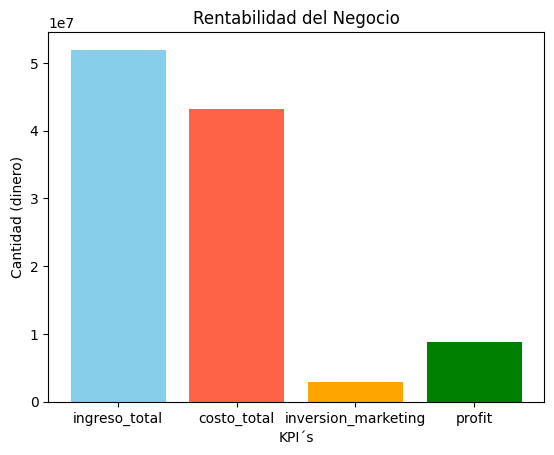

In [83]:
#Gráfico
kpis = ["ingreso_total", "costo_total", "inversion_marketing", "profit"]
monto = [51966981.56, 43124069.01, 2871843.53, 8842912.54]

porcentaje_profit = (monto[3] / monto[0]) * 100
porcentaje_marketing = (monto[2] / monto[1]) * 100

print(porcentaje_profit, porcentaje_marketing)

plt.bar(kpis, monto, color=["skyblue", "tomato", "orange", "green"])
plt.title("Rentabilidad del Negocio")
plt.xlabel("KPI´s")
plt.ylabel("Cantidad (dinero)")
plt.show()

**Interpretación:**  
De acuerdo a la gráfica se concluye que el negocio es rentable, pues presenta un ingreso total de 51,966,981.56 y un costo total de 43,124,069.01, lo cual arroja un profit positivo de 8,842,912.54, siendo este aproximadamente el 17% del total de los ingresos. Por otro lado, la inversión en marketing es de 2,871,843.53, representando solo el 6.66% de los costos totales.

In [84]:
# PARTE 2: COMPORTAMIENTO DE VENTAS
#Ticket promedio por orden
#Ingreso total dividido entre el número de órdenes (pedidos)
numero_pedidos= len(orders)

In [85]:
ticket_promedio= ingreso_total / numero_pedidos
print(ticket_promedio)

2083.1789288863947


In [86]:
#Cantidad promedio de productos por orden
prom_productos = orders['cantidad'].mean()
print(prom_productos)

7.116451535316283


In [87]:
#Producto más vendido
prod_mas_vendido= orders.groupby('nombre_producto')['cantidad'].sum().idxmax()
print(prod_mas_vendido)

Laptop-Gaming-16GB


In [88]:
#¿Cuánto se ha gastado en marketing por canal?
gasto_mark_por_canal= marketing.groupby('canal')['gasto'].sum()
print(gasto_mark_por_canal)

canal
desconocido    177179.10
organic        913533.01
paid_search    863088.21
social         918043.21
Name: gasto, dtype: float64


**Nota:**  
La categoria "desconocido" se presenta debido a que no existía registro en algunas filas y en lugar de eliminarlas se optó por clasificarlas de esa manera.

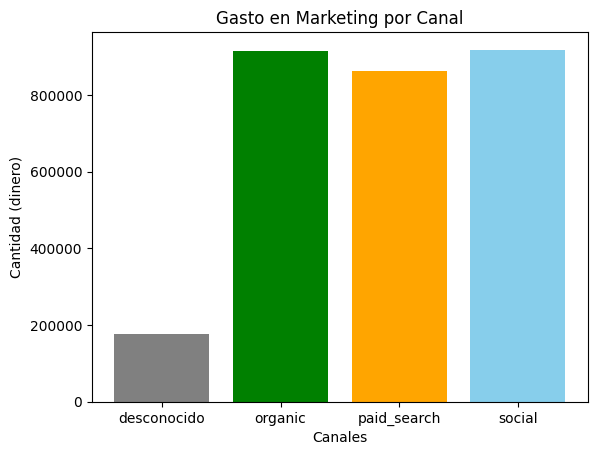

In [89]:
#Gráfico
canales = ["desconocido", "organic", "paid_search", "social"]
cantidad = [177179.10, 913533.01, 863088.21, 918043.21]

plt.bar(canales, cantidad, color=["grey", "green","orange", "skyblue"])
plt.title("Gasto en Marketing por Canal")
plt.xlabel("Canales")
plt.ylabel("Cantidad (dinero)")
plt.show()

**Interpretación:**
A excepción de la categoría "desconocido" con un monto de 177,179.10, los tres canales presentan una inversión más o menos parecida. Sin embargo, "social" es el canal con mayor gasto, con un total de 918,043.21, seguido de "organic" con 913,533.01 y por último se encuentra paid search con 863,088.21.  
Por otra parte, el ticket promedio es de  2,083.17, lo cual representa un monto alto comparado con el precio unitario de cada uno de los productos vendidos por la empresa, siendo el más alto Laptop-Gaming-16GB con un precio de 280.68 y también el producto más vendido más no rentable para el negocio. Así mismo, la cantidad promedio de productos por orden es de 7.11 productos, lo cual señala que los clientes realizan compras grandes.

<div class="alert alert-block alert-danger">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>


Para el paso 2 lo ideal sería agregar las gráficas siguiendo el objetivo del paso y lo que le interesa a la empresa revisar. Siempre una gráfica es mucho mejor que sólo mostrar valores numéricos.

Pero para complementar esta parte también puedes agregar tu interpretación de las gráficas mostradas en una celda markdown.

</div>


<div class="alert alert-block alert-success">
<b>Comentario del revisor (2da Iteracion)</b> <a class=“tocSkip”></a>

Correcto, siempre es importante tener un proceso de análisis claro y fácil de entender en todos tus notebooks para que cuando alguien de tu equipo quiera reproducir tu trabajo puedan entenderlo facilmente.
</div>

---

## 🔹 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?
---

In [90]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión (NO modificar)
# ======================
db_config = {
    'user': 'practicum_student',
    'pwd': 'QnmDH8Sc2TQLvy2G3Vvh7',
    'host': 'yp-trainers-practicum.cluster-czs0gxyx2d8w.us-east-1.rds.amazonaws.com',
    'port': 5432,
    'db': 'data-analyst-production-db-en'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [91]:
# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [92]:
# PARTE 1: Totales del funnel
# ======================

query_totals = '''
SELECT nombre_evento, 
    COUNT(DISTINCT id_usuario) AS usuarios_unicos
    FROM events GROUP BY nombre_evento
'''

totals = pd.read_sql(query_totals, con=engine)
totals

,nombre_evento,usuarios_unicos
0,add_payment_info,6250
1,add_to_cart,7634
2,begin_checkout,7208
3,first_visit,7796
4,purchase,6240
5,select_item,7582


In [93]:
# PARTE 1: Totales del funnel
# ======================

query_first_visit = '''
SELECT COUNT(DISTINCT id_usuario)
FROM events
WHERE nombre_evento = 'first_visit'
'''
total_first_visit = pd.read_sql(query_first_visit, con=engine)


query_select_item = '''
SELECT COUNT(DISTINCT id_usuario)
FROM events
WHERE nombre_evento = 'select_item'
  AND id_usuario IN (
      SELECT id_usuario FROM events WHERE nombre_evento = 'first_visit'
  )'''
total_select_item = pd.read_sql(query_select_item, con=engine)


query_add_to_cart ='''
SELECT COUNT(DISTINCT id_usuario)
FROM events
WHERE nombre_evento = 'add_to_cart'
  AND id_usuario IN (
      SELECT id_usuario FROM events WHERE nombre_evento = 'select_item'
  )'''
total_add_to_cart = pd.read_sql(query_add_to_cart, con=engine)


query_begin_checkout = '''
SELECT COUNT(DISTINCT id_usuario)
FROM events
WHERE nombre_evento = 'begin_checkout'
  AND id_usuario IN (
      SELECT id_usuario FROM events WHERE nombre_evento = 'add_to_cart'
  )'''
total_begin_checkout = pd.read_sql(query_begin_checkout, con=engine)


query_add_payment_info = '''
SELECT COUNT(DISTINCT id_usuario)
FROM events
WHERE nombre_evento = 'add_payment_info'
  AND id_usuario IN (
      SELECT id_usuario FROM events WHERE nombre_evento = 'begin_checkout'
  )'''
total_add_payment_info = pd.read_sql(query_add_payment_info, con=engine)


query_purchase = '''
SELECT COUNT(DISTINCT id_usuario)
FROM events
WHERE nombre_evento = 'purchase'
  AND id_usuario IN (
      SELECT id_usuario FROM events WHERE nombre_evento = 'add_payment_info'
  )'''
total_purchase = pd.read_sql(query_purchase, con=engine)

In [94]:
#Conteo
print(total_first_visit)
print(total_select_item)
print(total_add_to_cart)
print(total_begin_checkout)
print(total_add_payment_info)
print(total_purchase)

   count
0   7796
   count
0   7393
   count
0   7233
   count
0   6887
   count
0   5638
   count
0   4858


In [128]:
#Ordenar eventos según el flujo del usuario
datos = pd.DataFrame({
    'etapa': ['first_visit', 'select_item', 'add_to_cart', 'begin_checkout', 'add_payment_info', 'purchase'],
    'cantidad_usuarios': [total_first_visit.iloc[0,0], total_select_item.iloc[0,0], total_add_to_cart.iloc[0,0], total_begin_checkout.iloc[0,0],
                          total_add_payment_info.iloc[0,0], total_purchase.iloc[0,0]]
})
datos

,etapa,cantidad_usuarios
0,first_visit,7796
1,select_item,7393
2,add_to_cart,7233
3,begin_checkout,6887
4,add_payment_info,5638
5,purchase,4858


In [129]:
#PARTE 2
datos['usuarios_anterior'] = datos['cantidad_usuarios'].shift(1)

In [130]:
datos

,etapa,cantidad_usuarios,usuarios_anterior
0,first_visit,7796,NaN
1,select_item,7393,7796.0
2,add_to_cart,7233,7393.0
3,begin_checkout,6887,7233.0
4,add_payment_info,5638,6887.0
5,purchase,4858,5638.0


In [131]:
datos['porc_conversion'] = datos['cantidad_usuarios'] / datos['usuarios_anterior'] * 100

In [132]:
datos

,etapa,cantidad_usuarios,usuarios_anterior,porc_conversion
0,first_visit,7796,NaN,NaN
1,select_item,7393,7796.0,94.830682
2,add_to_cart,7233,7393.0,97.835791
3,begin_checkout,6887,7233.0,95.216369
4,add_payment_info,5638,6887.0,81.864382
5,purchase,4858,5638.0,86.165307


<div class="alert alert-block alert-danger">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Aquí hay que revisar cómo se está calculando las conversiones ya que lo esperado es conforme avance en el embudo la conversión disminuya y hay una conversión que excede el 100% lo cual se debe justificar el por qué o corregir el cálculo se se necesita, también te recomendaría agregar visualizaciones para que exponer los resultados sea más sencillo que solo exponer un resultado numérico.

Para complementar también deberías dejar una celda markdown con tus interpretaciones.
</div>

In [136]:
#En qué etapa se pierde la mayor cantidad de usuarios: add_payment_info
posicion= datos['porc_conversion'].idxmin()
datos.loc[posicion, 'etapa']

'add_payment_info'

In [144]:
#Tasa de conversión final
purch=datos.loc[datos['etapa'] == 'purchase', 'cantidad_usuarios']
purch= purch.iloc[0]
purch

4858

In [145]:
#Tasa de conversión final
first_v=datos.loc[datos['etapa'] == 'first_visit', 'cantidad_usuarios']
first_v= first_v.iloc[0]
first_v

7796

In [146]:
#Tasa de conversión final
tasa_conv= purch / first_v* 100
tasa_conv

62.31400718317086

**Interpretación:**  
Las etapas del funnel por las que debe pasar un usuario para llegar hasta el final, en este caso son seis. La primera etapa "first_visit" empezó con 7796 individuos, la segunda etapa "select_item" pasó con 7393 personas, a la tercera etapa "add_to_cart" llegaron 7233, a la cuarta etapa "begin_checkout" 6887, a la quinta etapa "add_payment_info" 5638 y a la última etapa "purchase" finalizaron 4858 usuarios; así mismo se aprecia que el cuello de botella se encuentra en la etapa "add_payment_info".  
La tasa de conversión global es razonable, pues presenta una cifra de 62.31%, la cual representa que más de la miatd de los usuarios que visitaron el sitio llegó a realizar una compra.  
Debido a estos hallazgos se recomienda revisar la etapa "add_payment_info", ya que probablemente existen complicaciones con la interfaz, modalidades de pago, entre otras, que impiden que más usuarios logren cruzar a la siguiente etapa.

<div class="alert alert-block alert-success">
<b>Comentario del revisor (2da Iteracion)</b> <a class=“tocSkip”></a>

Bien, siempre hay que asegurarse de que las métricas presentadas sean las correctas ya que eso es vital para una toma de decisiones adecuada en la empresa
</div>

---

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users` 
- `user_activity` 

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  

Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)`

In [107]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free


In [108]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT * 
FROM user_activity;
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1


In [109]:
# Retención por cohortes
#Total de usuarios
# ======================

query_cohort_retention_final = '''
WITH cohort AS (
    SELECT id_usuario, TO_CHAR(DATE_TRUNC('month', CAST(fecha_registro AS DATE)), 'YYYY-MM') AS cohort
    FROM users
),
cohort_semana AS (
    SELECT cohort.cohort, user_activity.id_usuario,
    CASE WHEN dias_despues_registro <= 7 THEN 'semana_1'
         WHEN dias_despues_registro <= 14 THEN 'semana_2'
         ELSE 'semana_3' END AS semana
    FROM cohort
    LEFT JOIN user_activity ON user_activity.id_usuario = cohort.id_usuario
),

totales_cohort AS (
    SELECT COUNT(id_usuario) AS total_usuarios, 
    TO_CHAR(DATE_TRUNC('month', 
    CAST(fecha_registro AS DATE)), 'YYYY-MM') AS cohort 
    FROM users 
    GROUP BY TO_CHAR(DATE_TRUNC('month', CAST(fecha_registro AS DATE)), 'YYYY-MM')
), 

retencion_semanal AS (
    SELECT cohort.cohort, COUNT(DISTINCT user_activity.id_usuario) AS usuarios_activos,
    CASE WHEN dias_despues_registro <= 7 THEN 'semana_1'
         WHEN dias_despues_registro <= 14 THEN 'semana_2'
         WHEN dias_despues_registro <= 21 THEN 'semana_3'
         ELSE 'más de 21 días' END AS semana
    FROM cohort
    LEFT JOIN user_activity ON user_activity.id_usuario = cohort.id_usuario WHERE user_activity.activo = 1 GROUP BY cohort.cohort, semana
)

SELECT * FROM totales_cohort
'''

# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final

,total_usuarios,cohort
0,1687,2025-05
1,1606,2025-04
2,1627,2025-01
3,1636,2025-03
4,1444,2025-02


In [110]:
# Retención por cohortes
#Usuarios activos
# ======================

query_cohort_retention_final = '''
WITH cohort AS (
    SELECT id_usuario, TO_CHAR(DATE_TRUNC('month', CAST(fecha_registro AS DATE)), 'YYYY-MM') AS cohort
    FROM users
),
cohort_semana AS (
    SELECT cohort.cohort, user_activity.id_usuario,
    CASE WHEN dias_despues_registro <= 7 THEN 'semana_1'
         WHEN dias_despues_registro <= 14 THEN 'semana_2'
         ELSE 'semana_3' END AS semana
    FROM cohort
    LEFT JOIN user_activity ON user_activity.id_usuario = cohort.id_usuario
),

totales_cohort AS (
    SELECT COUNT(id_usuario) AS total_usuarios, 
    TO_CHAR(DATE_TRUNC('month', 
    CAST(fecha_registro AS DATE)), 'YYYY-MM') AS cohort 
    FROM users 
    GROUP BY TO_CHAR(DATE_TRUNC('month', CAST(fecha_registro AS DATE)), 'YYYY-MM')
), 

retencion_semanal AS (
    SELECT cohort.cohort, COUNT(DISTINCT user_activity.id_usuario) AS usuarios_activos,
    CASE WHEN dias_despues_registro <= 7 THEN 'semana_1'
         WHEN dias_despues_registro <= 14 THEN 'semana_2'
         WHEN dias_despues_registro <= 21 THEN 'semana_3'
         ELSE 'más de 21 días' END AS semana
    FROM cohort
    LEFT JOIN user_activity ON user_activity.id_usuario = cohort.id_usuario WHERE user_activity.activo = 1 GROUP BY cohort.cohort, semana
)

SELECT * FROM retencion_semanal
'''

# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final

,cohort,usuarios_activos,semana
0,2025-01,671,más de 21 días
1,2025-01,697,semana_1
2,2025-01,668,semana_2
3,2025-01,656,semana_3
4,2025-02,575,más de 21 días
5,2025-02,611,semana_1
6,2025-02,609,semana_2
7,2025-02,635,semana_3
8,2025-03,673,más de 21 días
9,2025-03,677,semana_1


In [111]:
# Retención por cohortes
# ======================

query_cohort_retention_final = '''
WITH cohort AS (
    SELECT id_usuario, TO_CHAR(DATE_TRUNC('month', CAST(fecha_registro AS DATE)), 'YYYY-MM') AS cohort
    FROM users
),
cohort_semana AS (
    SELECT cohort.cohort, user_activity.id_usuario,
    CASE WHEN dias_despues_registro <= 7 THEN 'semana_1'
         WHEN dias_despues_registro <= 14 THEN 'semana_2'
         ELSE 'semana_3' END AS semana
    FROM cohort
    LEFT JOIN user_activity ON user_activity.id_usuario = cohort.id_usuario
),

totales_cohort AS (
    SELECT COUNT(id_usuario) AS total_usuarios, 
    TO_CHAR(DATE_TRUNC('month', 
    CAST(fecha_registro AS DATE)), 'YYYY-MM') AS cohort 
    FROM users 
    GROUP BY TO_CHAR(DATE_TRUNC('month', CAST(fecha_registro AS DATE)), 'YYYY-MM')
), 

retencion_semanal AS (
    SELECT cohort.cohort, COUNT(DISTINCT user_activity.id_usuario) AS usuarios_activos,
    CASE WHEN dias_despues_registro <= 7 THEN 'semana_1'
         WHEN dias_despues_registro <= 14 THEN 'semana_2'
         WHEN dias_despues_registro <= 21 THEN 'semana_3'
         ELSE 'más de 21 días' END AS semana
    FROM cohort
    LEFT JOIN user_activity ON user_activity.id_usuario = cohort.id_usuario WHERE user_activity.activo = 1 GROUP BY cohort.cohort, semana
)

SELECT retencion_semanal.cohort, semana, CAST(usuarios_activos AS FLOAT) / total_usuarios AS reten
FROM retencion_semanal
LEFT JOIN totales_cohort ON retencion_semanal.cohort = totales_cohort.cohort
WHERE semana <> 'más de 21 días'
'''

# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final

,cohort,semana,reten
0,2025-01,semana_1,0.428396
1,2025-01,semana_2,0.410572
2,2025-01,semana_3,0.403196
3,2025-02,semana_1,0.423130
4,2025-02,semana_2,0.421745
5,2025-02,semana_3,0.439751
6,2025-03,semana_1,0.413814
7,2025-03,semana_2,0.430929
8,2025-03,semana_3,0.421760
9,2025-04,semana_1,0.423412


In [112]:
#Porcentaje de retención para cada semana
retencion_pivot= cohorte_final.pivot(index='cohort', columns='semana', values='reten')*100
retencion_pivot

semana,semana_1,semana_2,semana_3
cohort,,,
2025-01,42.839582,41.057160,40.319607
2025-02,42.313019,42.174515,43.975069
2025-03,41.381418,43.092910,42.176039
2025-04,42.341220,43.399751,41.282690
2025-05,41.197392,40.071132,41.849437


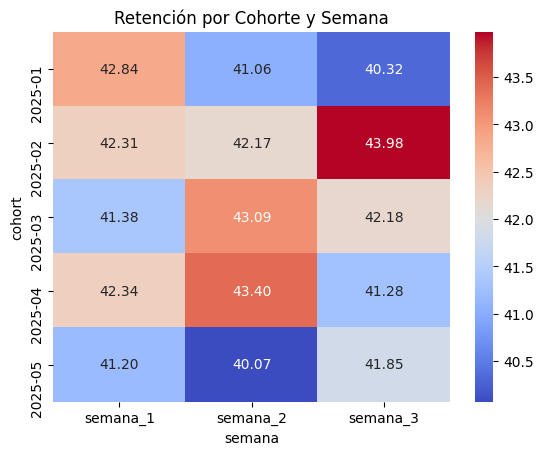

In [147]:
#Visualización
sns.heatmap(retencion_pivot, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Retención por Cohorte y Semana')
plt.show()

**Interpretación:**  
De acuerdo al heatmap, se aprecia que la semana más fuerte en retención es la semana 3 en la cohorte 2025-02 con un 43.98%, por el contrario, la más débil se encuentra en la semana 2 en la cohorte 2025-05 con un 40.07%. Esto señala que, no hay mucha diferencia en las retenciones entre las cohortes durante las 3 semanas, ya que los porcentajes se encuentran dentro de estos parámetros. Sin embargo, debería considerarse prestar atención a este punto, ya que en ningún momento se llega ni al 50% de retención.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

La query está muy bien y estás obteniendo resultados adecuados pero lo complementarías mejor si agregaras una visualización. Podrías utilizar una gráfica tipo mapa de calor por ejemplo para poder visualizar de mejor manera las semanas más fuertes de cada cohort.
</div>

---

## 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.    
2. **Plantear la hipótesis estadística**     
3. **Aplicar el test estadístico adecuado** 
4. **Interpretar el resultado**  

---
Hipótesis estadística
   - **H₀ (Hipótesis nula):** La modificación en la UI del checkout no impacta en la tasa de conversión de compra.
   - **H₁ (Hipótesis alternativa):** La modificación en la UI del checkout impacta en la tasa de conversión de compra.
   
**Test estadístico:** Test z para dos proporciones  
**Nivel de significancia alpha:** 0.05

In [113]:
# 1 Analizar el dataset para identificar la métrica "conversion"
exp_check_ui = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv')

In [114]:
exp_check_ui.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_usuario       10000 non-null  object 
 1   variante         10000 non-null  object 
 2   convirtio        10000 non-null  int64  
 3   dispositivo      10000 non-null  object 
 4   pais             10000 non-null  object 
 5   duracion_sesion  10000 non-null  float64
 6   timestamp        10000 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 547.0+ KB


In [115]:
exp_check_ui.head()

,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18
3,exp_user_3,tratamiento,0,mobile,Colombia,151.45,2025-06-03
4,exp_user_4,tratamiento,0,desktop,Mexico,299.96,2025-01-12


In [116]:
#Comprobar valores únicos en la columna "variante"
exp_check_ui['variante'].unique()

array(['tratamiento', 'control'], dtype=object)

In [117]:
# 3 Aplicar el Test estadístico adecuado
# Número de usuarios convertidos por página
conversiones = exp_check_ui.groupby('variante')['convirtio'].sum()

# Total de usuarios por página
totales = exp_check_ui.groupby('variante')['convirtio'].count()

print("Usuarios convertidos por página:\n", conversiones)
print("\nTotal de usuarios por página:\n", totales)

Usuarios convertidos por página:
 variante
control        779
tratamiento    820
Name: convirtio, dtype: int64

Total de usuarios por página:
 variante
control        4965
tratamiento    5035
Name: convirtio, dtype: int64


In [118]:
#Pasar los valores a formato lista
exitos = [conversiones['control'], conversiones['tratamiento']]
observaciones = [totales['control'], totales['tratamiento']]

In [119]:
#Imprimir valores
print("Éxitos (conversiones):", exitos)
print("Observaciones (totales):", observaciones)

Éxitos (conversiones): [779, 820]
Observaciones (totales): [4965, 5035]


In [120]:
# Aplicar prueba
z_stat, p_value = proportions_ztest(exitos , observaciones)

# Visualizar resultados
print(f"Estadístico : {z_stat}")
print(f"Valor p: {p_value}")

Estadístico : -0.8132782986429474
Valor p: 0.41605851639119995


In [121]:
#Porcentajes del estadístico z
porcentaje_control= conversiones['control'] / totales['control'] * 100 
porcentaje_tratamiento= conversiones['tratamiento'] / totales['tratamiento'] * 100

print(porcentaje_control)
print(porcentaje_tratamiento)

15.68982880161128
16.28599801390268


**4 Interpretar el resultado**  
No se rechaza la hipótesis nula, debido a que el valor p es de 0.4160, el cual es mayor al nivel de significancia de 0.05. Con los datos disponibles, la diferencia entre 15.69% y 16.29% se puede decir que es explicable por variación aleatoria, no por un efecto real de la UI. Por esta razón se recomienda seguir usando la variable de "control" o realizar una nueva versión de "tratamiento" y ponerla a prueba.

<div class="alert alert-block alert-success">
<b>Comentario del revisor (1ra Iteracion)</b> <a class="tocSkip"></a>

Muy buen trabajo con la aplicación de las pruebas estadísticas. Planteaste correctamente las hipótesis, elegiste la prueba adecuada e interpretaste los resultados con claridad.

Recuerda que este paso es clave en cualquier análisis de datos: las pruebas estadísticas permiten distinguir si las diferencias observadas son reales o producto del azar, lo que le da rigor y confianza a las conclusiones que se presentan al negocio.
</div>

---

## 🔹 Paso 6: Comunicar los resultados (Dashboard en BI)

🎯 **Objetivo**:  
Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión. 

Se usarán los CSVs limpios del Paso 1:

- `orders_clean.csv`  
- `catalog_clean.csv`  
- `marketing_clean.csv`

---

1️⃣ Preparación de los datos
1. Cargar los CSVs en Power BI o Tableau.
2. Revisar relaciones:
   - `orders.nombre_producto` → `catalog.nombre_producto`
   - `orders.fecha_pedido` → tabla de fechas (crear calendario para análisis temporal)
   - `orders.fecha_pedido` → `dim_fecha.date`
3. Crear columnas calculadas necesarias
4. Crear tabla de fechas para poder calcular comparaciones YTD, YoY o períodos anteriores (`Previous Year`, `Previous Month`).

---

2️⃣ Dashboard 1: Overview Ejecutivo
**KPIs principales a mostrar:**
- Revenue total
- Profit total
- Gasto total en marketing
- Ticket promedio
- Cantidad promedio de productos por orden

**Visualizaciones sugeridas:**
- Tarjetas KPI para revenue, profit y gasto marketing
- Gráfico de líneas: evolución mensual de revenue o profit
- Gráfico de líneas YTD
- Gráfico de barras: revenue y profit por producto o categoría

---

 3️⃣ Dashboard 2: Detalle / Drill-through  
**Objetivo:** Permitir explorar los datos desde el KPI general hasta cada orden o producto.

**Visualizaciones sugeridas:**
- Tabla detallada de órdenes con:
  - producto, cantidad, revenue, cost, profit
  - color condicional (profit negativo en rojo, positivo en verde)
- Gráfico de barras por producto con medida `cantidad vendida`
- Drill-through: seleccionar un producto y ver todos los pedidos relacionados
- Filtros por fecha, categoría de producto, etc

**Nota:**  
*Dashboard 1: Gráfico de barras*  
"Laptop-Gaming-16GB" genera el mayor revenue total pero un profit negativo, porque su precio de venta promedio, aproximadamente 258.37, está por debajo de su costo unitario aproximado de 280.68. Se recomienda revisar la estrategia de precios para este producto.

---

**Conclusiones y recomendaciones generales:**  
Respecto a la rentabilidad del negocio se puede afirmar que es rentable, ya que presenta un ingreso total de 51,966,981.56 y un costo total de 43,124,069.01, lo cual arroja un profit positivo de 8,842,912.54. Referente al marketing, su inversión es de 2,871,843.53, distribuido en tres canales:organic, paid search y social (y un desconocido, ya que no se presentaban esos registros) más o menos con la misma cantidad.  

El funnel por el que pasan los clientes para llegar hasta el final constó de seis etapas: first_visit, select_item, add_to_cart, begin_checkout, add_payment_info y purchase. Se inició con 7796 usuarios y finalizaron 4858 personas; presentando una tasa de conversión global de 62.31%. Así mismo, de estas etapas add_payment_info fue donde hubo mayor pérdida de clientes, por lo que se recomienda analizar la interfaz y otros aspectos que pudieran causar problemas para los usuarios.  

Hablando de la retención por cohortes, la semana más fuerte en retención fue la semana 3 en la cohorte 2025-02 con un 43.98% y la más débil se encontró en la semana 2 en la cohorte 2025-05 con un 40.07%, por lo que se aprecia no mucha diferencia entre los datos, pero debería prestarse atención a ello, debido a que en ningún momento se llega ni al 50% de retención.

Después de realizar el Test z para dos proporciones se puede señalar que la modificación en la UI del checkout no impacta en la tasa de conversión de compra, ya que su valor p fue de 0.4160, el cual es mayor al nivel de significancia de 0.05, por lo que se recomienda seguir usando la variable de "control" o realizar una nueva versión de "tratamiento".  

Gracias a la creación de los dashboards ejecutivo y detalle se concluye que el revenue total a lo largo de los meses, aunque pasó por una caída en febrero de 2025, se recuperó favorablemente; por su parte el profit desde el inicio tuvo un crecimiento de manera constante.  
De los 7 productos ofrecidos por la compañía, cuatro de ellos presentan revenue total de 1.6 millones con profits totales que van de los 0.4 millones a 1.5 millones, dejando en ambas categorías al resto de los productos con cantidades menores. Así mismo, tres de los productos lideran en la cantidad de ventas de productos con 6.3 mil, dejando por debajo un producto con 6.2 mil, dos prodcutos con 4.2 mil y uno con 4.1 mil.  
Así mismo, el producto llamado Vacuum Pro Black es el que genera el profit más alto para la empresa de 1,516,737.45, por el contrario Laptop Gaming 16GB presenta el profit más bajo, incluso de pérdidas, ya que se encuentra en -93,621.66; por esta razón se recomienda revisar mejor la logística de este producto para lograr disminuir estas pérdidas que se están presentando para la empresa.  

En conclusión, el negocio es rentable, sin embargo se debe poner atención al detalle de las pérdidas por Laptop Gaming 16GB y al cuello de botella de la etapa del funnel add_payment_info. Se recomienda el monitoreo constante de estos indicadores para reducir pérdidas y hacer crecer aún más a la empresa.

## 🚀 Entrega Final

Comparte el acceso a tu Dashboard para revisión.   
Puedes entregar el Dashboard utilizando **Power BI o Tableau**.

Incluye **uno de los siguientes**:

- 🔗 Link público del dashboard publicado en **Power BI Service o Tableau Public / Tableau Cloud**
- 🔗 Link de **Google Drive o OneDrive** con el archivo del proyecto (`.pbix`) y los 3 csvs limpios.


### 📎 Enlace del Dashboard

# (Pega aquí tu link)
# link de power bi o tableau
# link de one drive / google drive
https://drive.google.com/drive/folders/10zWQtt87kw5Wj9wG_jflNyWYvvDfpfrB?usp=sharing 

<div class="alert alert-block alert-success">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Muy buen trabajo con el dashboard, estás mostrando las gráficas monetarias necesarias para un buen seguimiento del desempeño de la empresa.

Cómo plus se podría también intentar conectar a la base de eventos y dejar un gráfico tipo funnel que muestre el comportamiento de los usuarios en el embudo principal de la empresa así además de métricas monetarias también pueden monitorear el desempeño de cada paso en su aplicación.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario general (1ra Iteracion)</b> <a class=“tocSkip”></a>

Tienes un muy buen avance de tu proyecto Yaritza. Hay algunos puntos con oportunidades de mejora donde te he dejado algunos comentarios.

También, al final deberías tener una sección con conclusiones y recomendaciones generales que puedas darle a la empresa en base a los diferentes pasos realizados a lo largo de tu notebook.


Si tienes dudas o dificultades recuerda que puedes contactar a tu Success Manager o a tu tutor para solventarlas.

Saludos!
</div>

<div class="alert alert-block alert-success">
<b>Comentario general (2da Iteracion)</b> <a class=“tocSkip”></a>

**¡Te felicito por el trabajo realizado Yaritza!** 

El paso a paso seguido en el proceso de análisis del proyecto quedó super claro y se ajusta a las necesidades del negocio presentadas. Recuerda que un buen análisis siempre debe tener una buena parte técnica que ayude a comprender la parte de negocio y los beneficios del mismo.

Con este proyecto demuestras las habilidades adquiridas durante tu formación, se nota tu capacidad de contar historias con datos con la excelente presentación realizada que súper fácil de entender lo cual es una habilidad super importante cómo analista de datos, el saber comunicar de manera sencilla y eficiente los resultados de tus análisis.
    
Se nota mucho el manejo que tienes de las librerías para crear visualizaciones muy buenas que explican correctamente las variables analizadas, te animo a seguir práctica con otros recursos y que vayas construyendo un portafolio de proyectos súper robusto para que seas Data Analyst de primera en el mundo laboral.
   
Saludos!
</div>